In [29]:
import pandas as pd
import re
from collections import defaultdict , Counter
import numpy as np
import torch
import esm
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from lightgbm import LGBMRegressor
from sklearn.model_selection import LeaveOneOut, cross_val_score, GroupKFold, cross_val_predict
from sklearn.metrics import mean_squared_error, r2_score
from scipy.stats import spearmanr
import optuna
import json
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df_General = pd.read_csv('opt_train_test.csv')
df_GOX = pd.read_csv('56_GOX.csv')
df_GOX.columns

Index(['uniprot_id', 'organism', 'ec_number', 'enzyme_name', 'sequence',
       'temp_opt_C', 'seq_length', 'ph_opt', 'km_mM', 'kcat_per_s',
       'temp_range_min_C', 'temp_range_max_C', 'temp_range_span',
       'ec_1.1.3.10', 'ec_1.1.3.10.1', 'ec_1.1.3.10.2', 'ec_1.1.3.13',
       'ec_1.1.3.13.1', 'ec_1.1.3.13.2', 'ec_1.1.3.4', 'ec_1.1.3.4.1',
       'ec_1.1.3.4.2', 'ec_1.1.3.6', 'ec_1.1.3.6.1', 'ec_1.1.3.6.2',
       'ec_1.1.99.18', 'ec_1.1.99.18.1', 'ec_1.1.99.18.2'],
      dtype='object')

In [3]:
df_gox = df_GOX.drop(columns=['uniprot_id', 'organism', 'ec_number', 'enzyme_name',
                              'seq_length', 'ph_opt', 'km_mM', 'kcat_per_s',
                              'temp_range_min_C', 'temp_range_max_C', 'temp_range_span',
                              'ec_1.1.3.10', 'ec_1.1.3.10.1', 'ec_1.1.3.10.2', 'ec_1.1.3.13',
                              'ec_1.1.3.13.1', 'ec_1.1.3.13.2', 'ec_1.1.3.4', 'ec_1.1.3.4.1',
                              'ec_1.1.3.4.2', 'ec_1.1.3.6', 'ec_1.1.3.6.1', 'ec_1.1.3.6.2',
                              'ec_1.1.99.18', 'ec_1.1.99.18.1', 'ec_1.1.99.18.2'])
df_general = df_General.rename(columns={'label': 'temp_opt_C', 'seq':'sequence'})

In [4]:
df_general['id'] = [f'general_{i}' for i in range(len(df_general))]
df_gox['id'] = [f'gox_{i}' for i in range(len(df_gox)) ]

df_all = pd.concat([df_general, df_gox], ignore_index=True, axis=0)

In [5]:
df_all.shape

(1952, 3)

In [6]:
df_all.head()

,sequence,temp_opt_C,id
0,MLVRSFLGFAVLAATCLAASLQEVTEFGDNPTNIQMYIYVPDQLDT...,55.0,general_0
1,MLPHLLLAAAQLFASSSAALTYNGADISSLLVEEGKGVSYKNLAGT...,40.0,general_1
2,MDTAEERLKGQAEIWEHMFAFVDSMALKCAVELGIPDIINSHGRPV...,39.0,general_2
3,MKRNLFRIVSRVVLIAFIASISLVGAMSYFPVETQAAPDWSIPSLC...,82.5,general_3
4,LKPQKEITRAEVVKLLSKIASLIVTKPGVYTLSKSEGFVIVNSGDV...,75.0,general_4


In [7]:
print(df_all['sequence'].duplicated().sum())
print(df_all.isnull().sum())

20
sequence      0
temp_opt_C    0
id            0
dtype: int64


In [8]:
df_all = df_all.drop_duplicates(subset='sequence').reset_index(drop=True)
df_all = df_all[(df_all['temp_opt_C'] >= 0) & (df_all['temp_opt_C'] <= 110)].reset_index(drop=True)
print(f'general : {df_all["id"].str.startswith("general").sum()}')
print(f'gox : {df_all["id"].str.startswith("gox").sum()}')

general : 1884
gox : 46


In [9]:
df = df_all.to_csv(
    'general_gox.csv',
    index=False
)


In [ ]:
# in google colab
!apt-get install -y cd-hit -qq
!cd-hit -i all_sequences_clean.fasta -o clustered_output -c 0.7 -n 5 -d 0

In [11]:
# in google colab
!head -20 clustered_output.clstr

'head' is not recognized as an internal or external command,
operable program or batch file.


In [11]:

seq_to_cluster = {}
current_cluster = None
with open("clustered_output.clstr") as f:
    for line in f:
        if line.startswith(">Cluster"):
            current_cluster = int(line.strip().split()[1])
        else:
            match = re.search(r">(\S+)\.\.\.", line)
            if match:
                seq_to_cluster[match.group(1)] = current_cluster

df_all["cluster"] = df_all["id"].map(seq_to_cluster)

print(f"clusters : {df_all['cluster'].nunique()}")
print(df_all["cluster"].isna().sum())  #==> it must be 0

clusters : 1737
0


In [12]:
gox_clusters = set(df_all[df_all['id'].str.startswith('gox_')]['cluster'])
general_clusters = set(df_all[df_all['id'].str.startswith('general_')]['cluster'])

shared_clusters = gox_clusters & general_clusters
print(len(shared_clusters))

gox_in_shared = df_all[(df_all['id'].str.startswith('gox_')) & (df_all['cluster'].isin(shared_clusters))]
print(len(gox_in_shared))
#this result is so importent  for methods 
# Reason for homology leakage: 39% of GOX samples fall in the same CD-HIT cluster (70% identity threshold) as at least one sequence from the public dataset; a random split could therefore leak data.

8
18


In [13]:
AMINO_ACIDS = 'ACDEFGHIKLMNPQRSTVWY'

def compute_aac(seq):
    counts = Counter(seq)
    total = len(seq)
    return [counts.get(aa, 0)/ total for aa in AMINO_ACIDS]

aac_features = np.array([compute_aac(s) for s in df_all['sequence']])
aac_features.shape
# Methods note: all 1932 sequences (before removing 2 temperature outliers) were used for CD-HIT; the final dataset has 1930 samples after cleaning.

(1930, 20)

In [14]:
AMINO_ACIDS = 'ACDEFGHIKLMNPQRSTVWY'
aac_df = pd.DataFrame(aac_features, columns=[f'aac_{aa}'for aa in AMINO_ACIDS])
df_all = pd.concat([df_all.reset_index(drop=True), aac_df], axis=1)
df2 = df_all.to_csv(
    'general_gox_aac.csv',
    index=False
)

In [15]:
df_all

,sequence,temp_opt_C,id,cluster,aac_A,aac_C,aac_D,aac_E,aac_F,aac_G,...,aac_M,aac_N,aac_P,aac_Q,aac_R,aac_S,aac_T,aac_V,aac_W,aac_Y
0,MLVRSFLGFAVLAATCLAASLQEVTEFGDNPTNIQMYIYVPDQLDT...,55.00,general_0,1419,0.082474,0.020619,0.048110,0.037801,0.048110,0.116838,...,0.027491,0.041237,0.054983,0.085911,0.024055,0.072165,0.065292,0.065292,0.020619,0.037801
1,MLPHLLLAAAQLFASSSAALTYNGADISSLLVEEGKGVSYKNLAGT...,40.00,general_1,1139,0.093750,0.008523,0.073864,0.034091,0.031250,0.082386,...,0.008523,0.056818,0.042614,0.034091,0.019886,0.090909,0.065341,0.059659,0.028409,0.053977
2,MDTAEERLKGQAEIWEHMFAFVDSMALKCAVELGIPDIINSHGRPV...,39.00,general_2,1130,0.070423,0.022535,0.061972,0.064789,0.045070,0.061972,...,0.030986,0.050704,0.050704,0.019718,0.036620,0.056338,0.050704,0.056338,0.022535,0.016901
3,MKRNLFRIVSRVVLIAFIASISLVGAMSYFPVETQAAPDWSIPSLC...,82.50,general_3,44,0.054860,0.009625,0.060635,0.047161,0.036574,0.062560,...,0.014437,0.066410,0.068335,0.028874,0.028874,0.076997,0.083734,0.058710,0.037536,0.053898
4,LKPQKEITRAEVVKLLSKIASLIVTKPGVYTLSKSEGFVIVNSGDV...,75.00,general_4,8,0.046164,0.002601,0.057867,0.055917,0.039662,0.081274,...,0.011704,0.072822,0.048765,0.048765,0.026008,0.082575,0.072822,0.086476,0.018205,0.044863
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1925,MSTSSSDPFFNFAKSSFRSAAAQKASASSLPPLPGPDKKVPGMDIK...,28.75,gox_47,316,0.064205,0.014446,0.062600,0.056180,0.057785,0.065811,...,0.027287,0.049759,0.070626,0.046549,0.044944,0.080257,0.072231,0.065811,0.014446,0.024077
1926,MPIRLSKEKINDLLQRSQGDLTSSQDEIVHYTDVFIAGSGPIACTY...,50.00,gox_49,424,0.076241,0.014184,0.072695,0.039007,0.031915,0.063830,...,0.019504,0.051418,0.072695,0.046099,0.049645,0.056738,0.085106,0.092199,0.012411,0.024823
1927,MKTILSSSLVVSMAAACTLHRSSGIEASLLTDPKAVAGRTVDDIIA...,37.00,gox_50,342,0.100993,0.006623,0.062914,0.049669,0.029801,0.089404,...,0.018212,0.052980,0.041391,0.036424,0.036424,0.067881,0.076159,0.086093,0.014901,0.041391
1928,MAIPEEFDIIVVGGGSAGCPTAGRLANLDPNLTVALIEAGENNINN...,25.00,gox_52,263,0.078431,0.019608,0.069382,0.052790,0.040724,0.076923,...,0.027149,0.046757,0.073906,0.021116,0.040724,0.067873,0.058824,0.051282,0.015083,0.048265


In [ ]:
#in google colab

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"use of: {device}")

model, alphabet = esm.pretrained.esm2_t30_150M_UR50D()
batch_converter = alphabet.get_batch_converter()
model = model.to(device)
model.eval()

def get_esm_embedding(seq, max_len=1024):
    seq = seq[:max_len]
    _, _, tokens = batch_converter([("id", seq)])
    tokens = tokens.to(device)
    with torch.no_grad():
        results = model(tokens, repr_layers=[30])
    rep = results["representations"][30][0, 1:len(seq)+1]
    return rep.mean(0).cpu().numpy()

esm_features = np.array([get_esm_embedding(s) for s in df_all["sequence"]])
print(esm_features.shape) 

In [ ]:
esm_df = pd.DataFrame(esm_features, columns=[f"esm_{i}" for i in range(esm_features.shape[1])])
df_all = pd.concat([df_all.reset_index(drop=True), esm_df], axis=1)

In [ ]:
#csv files of general_gox_esm with and without aac are created in google colab

In [16]:
df_esm_aac = pd.read_csv('general_gox_aac_esm.csv')

In [17]:
MAX_LEN=1024

In [18]:
n_truncated = (df_esm_aac['sequence'].str.len() > MAX_LEN).sum()
pct_truncated = 100 * n_truncated / len(df_esm_aac)
print(f"sequences truncated at {MAX_LEN}: {n_truncated} ({pct_truncated:.2f}%)")

sequences truncated at 1024: 56 (2.90%)


In [23]:
#X and y for general and gox
general_mask = df_esm_aac['id'].str.startswith('general_')
gox_mask = df_esm_aac['id'].str.startswith('gox_')

aac_cols = [c for c in df_esm_aac.columns if c.startswith("aac_") ]
esm_cols = [c for c in df_esm_aac.columns if c.startswith("esm_")]

X_general_aac = df_esm_aac.loc[general_mask, aac_cols].values
X_gox_aac = df_esm_aac.loc[gox_mask, aac_cols].values
X_general_esm = df_esm_aac.loc[general_mask, esm_cols].values
X_gox_esm = df_esm_aac.loc[gox_mask, esm_cols].values
X_gox_combined = df_esm_aac.loc[gox_mask, aac_cols + esm_cols].values
X_general_combined = df_esm_aac.loc[general_mask, aac_cols + esm_cols].values

y_general = df_esm_aac.loc[general_mask, 'temp_opt_C'].values
y_gox = df_esm_aac.loc[gox_mask, 'temp_opt_C'].values

cluster_general = df_esm_aac.loc[general_mask, 'cluster'].values
cluster_gox = df_esm_aac.loc[gox_mask, 'cluster'].values


In [24]:
oracle_preds, oracle_actuals = [], []

for i in range(len(y_gox)):
    if cluster_gox[i] in shared_clusters:
        general_members = y_general[cluster_general == cluster_gox[i]]
        oracle_preds.append(general_members.mean())  
        oracle_actuals.append(y_gox[i])

oracle_rmse = np.sqrt(mean_squared_error(oracle_actuals, oracle_preds))
print(f"ORACLE_RMSE (homology transfer, n={len(oracle_actuals)} of 46 GOx samples): {oracle_rmse:.2f}")

oracle_actuals_arr = np.array(oracle_actuals)
oracle_preds_arr = np.array(oracle_preds)

def bootstrap_rmse_ci(actual, pred, n_boot=10000, seed=42):
    rng = np.random.RandomState(seed)
    n = len(actual)
    rmses = [np.sqrt(mean_squared_error(actual[idx], pred[idx])) for idx in
              (rng.choice(n, size=n, replace=True) for _ in range(n_boot))]
    return tuple(np.percentile(rmses, [2.5, 97.5]))

oracle_ci = bootstrap_rmse_ci(oracle_actuals_arr, oracle_preds_arr)
print(f"ORACLE_RMSE 95% CI: {oracle_ci}")

ORACLE_RMSE (homology transfer, n=18 of 46 GOx samples): 12.67
ORACLE_RMSE 95% CI: (6.52048032684291, 18.470902091275434)


In [25]:
#Pipeline
pipeline_aac = Pipeline([
    ('scaler',StandardScaler()),
    ('model', LGBMRegressor(random_state=42))
])

pipeline_esm = Pipeline([
    ('scaler',StandardScaler()),
    ("pca", PCA(n_components=50, random_state=42)),
    ('model', LGBMRegressor(random_state=42))
])

pipeline_combined = Pipeline([
    ('scaler',StandardScaler()),
    ("pca", PCA(n_components=50, random_state=42)),
    ('model', LGBMRegressor(random_state=42))
])

In [26]:
#LOOCV
def run_cluster_aware_loocv_with_predictions(pipeline, X_general, y_general, cluster_general,
                              X_gox, y_gox, cluster_gox, gox_ids):
    loo = LeaveOneOut()
    preds, actuals, ids = [], [], []

    for train_idx, test_idx in loo.split(X_gox):
        test_cluster = cluster_gox[test_idx[0]]
        general_keep = cluster_general != test_cluster
        gox_train_keep = cluster_gox[train_idx] != test_cluster

        X_train = np.vstack([X_general[general_keep], X_gox[train_idx][gox_train_keep]])
        y_train = np.concatenate([y_general[general_keep], y_gox[train_idx][gox_train_keep]])
       
        pipeline.fit(X_train, y_train)
        pred = pipeline.predict(X_gox[test_idx])
        preds.append(pred[0])
        actuals.append(y_gox[test_idx][0])
        ids.append(gox_ids[test_idx[0]])

    return pd.DataFrame({
            'id': ids,
            'actual_temp': actuals,
            'predicted_temp': preds,
            'residual': np.array(actuals) - np.array(preds),
})

        
def summarize_predictions(predictions_df):
    rmse = np.sqrt(mean_squared_error(predictions_df['actual_temp'], predictions_df['predicted_temp']))
    r2 = r2_score(predictions_df['actual_temp'], predictions_df['predicted_temp'])
    spearman = spearmanr(predictions_df['actual_temp'], predictions_df['predicted_temp']).correlation
    return {"RMSE": rmse, "R2": r2, "Spearman": spearman}   



In [27]:
loo = LeaveOneOut()
baseline_preds_loo = []
actuals_loo = []

for train_idx, test_idx in loo.split(X_gox_aac):
    train_mean = y_gox[train_idx].mean()
    baseline_preds_loo.append(train_mean)
    actuals_loo.append(y_gox[test_idx][0])

baseline_rmse_loo = np.sqrt(mean_squared_error(actuals_loo, baseline_preds_loo))
print(f"correct LOOCV baseline RMSE: {baseline_rmse_loo:.2f}")

correct LOOCV baseline RMSE: 13.64


In [ ]:

#OPTUNA
gkf = GroupKFold(n_splits=5)
def objective_aac(trial):
    params = {
        'model__n_estimators': trial.suggest_int('n_estimators', 50, 500),
        'model__max_depth': trial.suggest_int('max_depth', 3, 12),
        'model__learning_rate': trial.suggest_float('learning_rate', 0.01, 0.3, log=True),
        'model__num_leaves': trial.suggest_int('num_leaves', 15, 100),
    }
    pipeline_aac.set_params(**params)
    return cross_val_score(pipeline_aac, X_general_aac, y_general, cv=gkf, groups=cluster_general, scoring='r2').mean()

def objective_esm(trial):
    params = {
        'pca__n_components': trial.suggest_int('n_components', 20, 100),
        'model__n_estimators': trial.suggest_int('n_estimators', 50, 500),
        'model__max_depth': trial.suggest_int('max_depth', 3, 12),
        'model__learning_rate': trial.suggest_float('learning_rate', 0.01, 0.3, log=True),
        'model__num_leaves': trial.suggest_int('num_leaves', 15, 100),
    }
    pipeline_esm.set_params(**params)
    return cross_val_score(pipeline_esm, X_general_esm, y_general, cv=gkf, groups=cluster_general, scoring='r2').mean()


def objective_combined(trial):
    params = {
        'pca__n_components': trial.suggest_int('n_components', 20, 100),
        'model__n_estimators': trial.suggest_int('n_estimators', 50, 500),
        'model__max_depth': trial.suggest_int('max_depth', 3, 12),
        'model__learning_rate': trial.suggest_float('learning_rate', 0.01, 0.3, log=True),
        'model__num_leaves': trial.suggest_int('num_leaves', 15, 100),
    }
    pipeline_combined.set_params(**params)
    return cross_val_score(pipeline_combined, X_general_combined, y_general, cv=gkf, groups=cluster_general, scoring='r2').mean()


study_aac = optuna.create_study(direction='maximize', sampler=optuna.samplers.TPESampler(seed=42))
study_aac.optimize(objective_aac, n_trials=50)
pipeline_aac.set_params(**{f'model__{k}': v for k,v in study_aac.best_params.items()})

study_esm = optuna.create_study(direction='maximize', sampler=optuna.samplers.TPESampler(seed=42))
study_esm.optimize(objective_esm, n_trials=50)
esm_best = {f"{'pca'if k== 'n_components' else 'model'}__{k}": v for k, v  in study_esm.best_params.items()}
pipeline_esm.set_params(**esm_best)

study_combined = optuna.create_study(direction='maximize', sampler=optuna.samplers.TPESampler(seed=42))
study_combined.optimize(objective_combined, n_trials=50)
combined_best = {f"{'pca'if k== 'n_components' else 'model'}__{k}": v for k, v  in study_combined.best_params.items()}
pipeline_combined.set_params(**combined_best)

In [ ]:

y_general_pred = cross_val_predict(pipeline_combined, X_general_combined, y_general,
                                     cv=gkf, groups=cluster_general)
r2_general = r2_score(y_general, y_general_pred)
rmse_general = np.sqrt(mean_squared_error(y_general, y_general_pred))

print(f"R2_GENERAL: {r2_general:.3f}")
print(f"RMSE_GENERAL: {rmse_general:.2f}")

def bootstrap_r2_ci(y_true, y_pred, n_boot=10000, seed=42):
    rng = np.random.RandomState(seed)
    n = len(y_true)
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    r2s = [r2_score(y_true[idx], y_pred[idx]) for idx in
           (rng.choice(n, size=n, replace=True) for _ in range(n_boot))]
    return tuple(np.percentile(r2s, [2.5, 97.5]))

r2_general_ci = bootstrap_r2_ci(y_general, y_general_pred)
print(f"R2_GENERAL 95% CI: {r2_general_ci}")

In [24]:
gox_ids = df_esm_aac.loc[gox_mask, 'id'].values

In [ ]:

predictions_aac = run_cluster_aware_loocv_with_predictions(pipeline_aac, X_general_aac, y_general, cluster_general,X_gox_aac, y_gox, cluster_gox, gox_ids)
predictions_esm = run_cluster_aware_loocv_with_predictions(pipeline_esm, X_general_esm, y_general, cluster_general,X_gox_esm, y_gox, cluster_gox, gox_ids)
predictions_combined = run_cluster_aware_loocv_with_predictions(pipeline_combined, X_general_combined, y_general, cluster_general,X_gox_combined, y_gox, cluster_gox, gox_ids)

predictions_aac.to_csv('gox_samples_predictions_aac.csv', index=False)
predictions_esm.to_csv('gox_samples_predictions_esm.csv', index=False)
predictions_combined.to_csv('gox_samples_predictions_combined.csv', index=False)

result_aac = summarize_predictions(predictions_aac)
result_esm = summarize_predictions(predictions_esm)
result_combined = summarize_predictions(predictions_combined)

print('AAC only:', result_aac)
print('ESM only:', result_esm)
print('ESM + AAC:', result_combined)

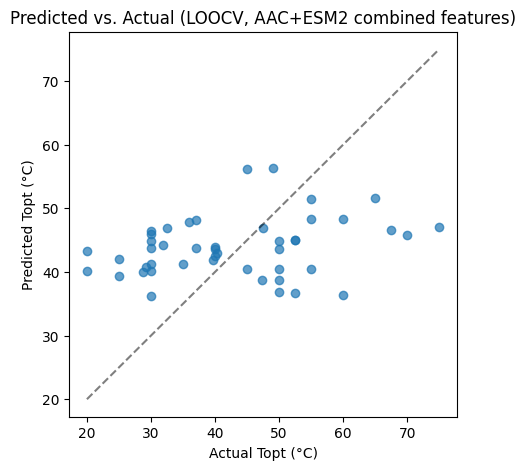

In [26]:
plt.figure(figsize=(5, 5))
plt.scatter(predictions_combined["actual_temp"], predictions_combined["predicted_temp"], alpha=0.7)
lims = [predictions_combined[["actual_temp", "predicted_temp"]].min().min(),
        predictions_combined[["actual_temp", "predicted_temp"]].max().max()]
plt.plot(lims, lims, 'k--', alpha=0.5)
plt.xlabel("Actual Topt (°C)")
plt.ylabel("Predicted Topt (°C)")
plt.title("Predicted vs. Actual (LOOCV, AAC+ESM2 combined features)")
plt.savefig("figure3_scatter.png", dpi=300, bbox_inches='tight')
plt.show()

In [29]:
X_general_aac = df_esm_aac.loc[general_mask, aac_cols].values
X_gox_aac = df_esm_aac.loc[gox_mask, aac_cols].values
gox_sizes = [0, 10, 20, 30, 45]
n_seeds = 10
scaling_results = []
combined_pca_n = combined_best.get('pca__n_components', 50)
model_params = {k.replace('model__',''): v for k, v in combined_best.items() if k.startswith('model__')}
for k in gox_sizes:
    fold_rmses = []
    n_seeds_k = 1 if k in (0,45) else n_seeds
    for seed in range(n_seeds_k):
        rng_k = np.random.RandomState(seed)
        preds, actuals = [], []

        for train_idx, test_idx in loo.split(X_gox_combined):
            available_idx = train_idx
            chosen = (rng_k.choice(available_idx, size=min(k, len(available_idx)), replace=False)
                      if k > 0 else np.array([], dtype=int))

            test_cluster = cluster_gox[test_idx[0]]
            general_keep = cluster_general != test_cluster
            if len(chosen) > 0:
                chosen = chosen[cluster_gox[chosen] != test_cluster]

            X_train_parts = [X_general_combined[general_keep]]
            y_train_parts = [y_general[general_keep]]
            if len(chosen) > 0:
                X_train_parts.append(X_gox_combined[chosen])
                y_train_parts.append(y_gox[chosen])

            X_train = np.vstack(X_train_parts)
            y_train = np.concatenate(y_train_parts)

            pipe_k = Pipeline([
                ('scaler', StandardScaler()),
                ("pca", PCA(n_components=combined_pca_n, svd_solver='randomized', random_state=42)),
                ("model", LGBMRegressor(random_state=42, n_jobs=-1, verbose=-1, **model_params))
            ])
            pipe_k.fit(X_train, y_train)
            pred = pipe_k.predict(X_gox_combined[test_idx])
            preds.append(pred[0])
            actuals.append(y_gox[test_idx][0])

        fold_rmses.append(np.sqrt(mean_squared_error(actuals, preds)))

    scaling_results.append({
        "k_gox_samples": k, "rmse_mean": np.mean(fold_rmses), "rmse_std": np.std(fold_rmses),
    })
    print(f"k={k}: RMSE = {np.mean(fold_rmses):.2f} ± {np.std(fold_rmses):.2f}")

k=0: RMSE = 13.40 ± 0.00
k=10: RMSE = 13.34 ± 0.43
k=20: RMSE = 12.99 ± 0.52
k=30: RMSE = 13.09 ± 0.22
k=45: RMSE = 12.95 ± 0.00


In [32]:
scaling_df = pd.DataFrame(scaling_results)
scaling_df.to_csv("scaling_curve_combined.csv", index=False)
print(scaling_df)

   k_gox_samples  rmse_mean  rmse_std
0              0  13.404581  0.000000
1             10  13.337951  0.425172
2             20  12.991750  0.516770
3             30  13.087344  0.223042
4             45  12.948439  0.000000


In [33]:
def run_loocv_no_general_filter(pipeline, X_general, y_general, X_gox, y_gox, cluster_gox, gox_ids):
    loo = LeaveOneOut()
    preds, actuals, ids = [], [], []
    for train_idx, test_idx in loo.split(X_gox):
        test_cluster = cluster_gox[test_idx[0]]
        gox_train_keep = cluster_gox[train_idx] != test_cluster  

        X_train = np.vstack([X_general, X_gox[train_idx][gox_train_keep]])  
        y_train = np.concatenate([y_general, y_gox[train_idx][gox_train_keep]])

        pipeline.fit(X_train, y_train)
        pred = pipeline.predict(X_gox[test_idx])
        preds.append(pred[0]); actuals.append(y_gox[test_idx][0]); ids.append(gox_ids[test_idx[0]])

    return pd.DataFrame({"id": ids, "actual_temp": actuals, "predicted_temp": preds,
                          "residual": np.array(actuals) - np.array(preds)})

preds_aac_nofilter = run_loocv_no_general_filter(pipeline_aac, X_general_aac, y_general, X_gox_aac, y_gox, cluster_gox, gox_ids)
preds_esm_nofilter = run_loocv_no_general_filter(pipeline_esm, X_general_esm, y_general, X_gox_esm, y_gox, cluster_gox, gox_ids)
preds_combined_nofilter = run_loocv_no_general_filter(pipeline_combined, X_general_combined, y_general, X_gox_combined, y_gox, cluster_gox, gox_ids)

for name, p in [("AAC", preds_aac_nofilter), ("ESM2", preds_esm_nofilter), ("Combined", preds_combined_nofilter)]:
    p.to_csv(f"gox_predictions_{name.lower()}_nofilter.csv", index=False)
    print(name, summarize_predictions(p))

AAC {'RMSE': 13.601551450260294, 'R2': -0.038881596132553264, 'Spearman': 0.19974722111983784}
ESM2 {'RMSE': 13.159739821222857, 'R2': 0.027513096279258464, 'Spearman': 0.20979150990970616}
Combined {'RMSE': 13.156661038401799, 'R2': 0.02796807879023422, 'Spearman': 0.22042952279427855}


In [35]:

cluster_sizes = df_all['cluster'].value_counts()
multi_member_clusters = cluster_sizes[cluster_sizes > 1].index

within_cluster_diffs = []
cluster_temp_data = []

for c in multi_member_clusters:
    members = df_all[df_all['cluster'] == c]
    temps = members['temp_opt_C'].values

    for t in temps:
        cluster_temp_data.append({"cluster": c, "temp_opt_C": t, "size": len(temps)})
    if len(temps) >= 2:
        for i in range(len(temps)):
            for j in range(i+1, len(temps)):
                within_cluster_diffs.append(abs(temps[i] - temps[j]))

cluster_df = pd.DataFrame(cluster_temp_data)
within_cluster_diffs = np.array(within_cluster_diffs)

print(f"Number of multi member clusters: {len(multi_member_clusters)}")
print(f"Mean of cluster differs: {within_cluster_diffs.mean():.2f} °C")
print(f"median: {np.median(within_cluster_diffs):.2f} °C")


Number of multi member clusters: 137
Mean of cluster differs: 9.93 °C
median: 5.00 °C


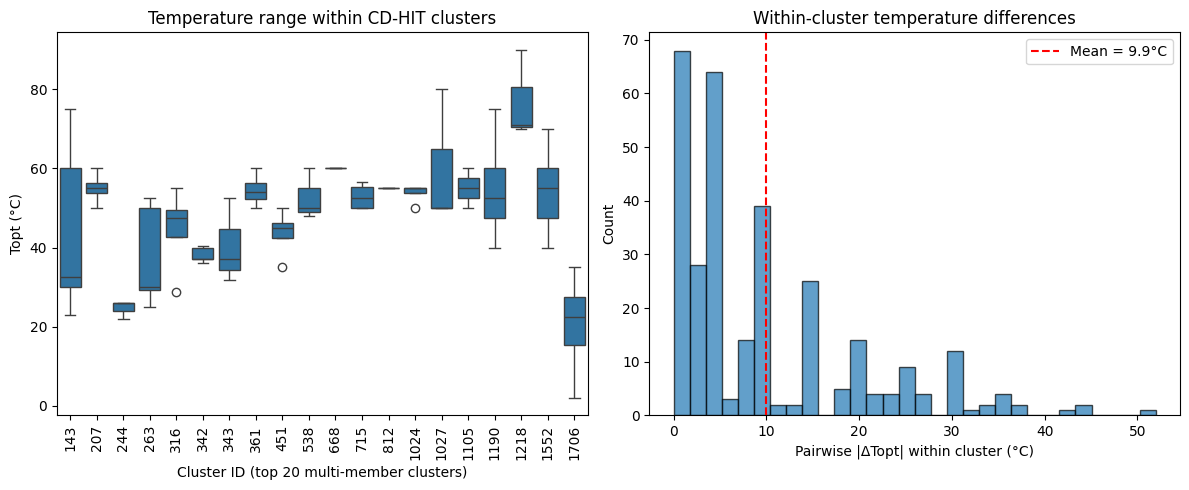

In [37]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

top_clusters = cluster_sizes[cluster_sizes > 1].nlargest(20).index
plot_data = cluster_df[cluster_df['cluster'].isin(top_clusters)]
sns.boxplot(data=plot_data, x='cluster', y='temp_opt_C', ax=axes[0])
axes[0].set_xlabel("Cluster ID (top 20 multi-member clusters)")
axes[0].set_ylabel("Topt (°C)")
axes[0].set_title("Temperature range within CD-HIT clusters")
axes[0].tick_params(axis='x', rotation=90)

axes[1].hist(within_cluster_diffs, bins=30, edgecolor='black', alpha=0.7)
axes[1].axvline(within_cluster_diffs.mean(), color='red', linestyle='--', label=f'Mean = {within_cluster_diffs.mean():.1f}°C')
axes[1].set_xlabel("Pairwise |ΔTopt| within cluster (°C)")
axes[1].set_ylabel("Count")
axes[1].set_title("Within-cluster temperature differences")
axes[1].legend()

plt.tight_layout()
plt.savefig("figure4_within_cluster.png", dpi=300, bbox_inches='tight')
plt.show()

In [38]:
def permutation_control(pipeline, X_general, y_general, cluster_general,
                          X_gox, y_gox, cluster_gox, gox_ids, n_permutations=100, seed=42):
    rng = np.random.RandomState(seed)
    null_r2s = []
    null_spearmans = []

    for i in range(n_permutations):
        y_gox_shuffled = rng.permutation(y_gox)  

        preds_df = run_cluster_aware_loocv_with_predictions(
            pipeline, X_general, y_general, cluster_general,
            X_gox, y_gox_shuffled, cluster_gox, gox_ids
        )
        null_r2s.append(r2_score(preds_df["actual_temp"], preds_df["predicted_temp"]))
        sp = spearmanr(preds_df["actual_temp"], preds_df["predicted_temp"]).correlation
        null_spearmans.append(sp if not np.isnan(sp) else 0.0)

        if (i + 1) % 20 == 0:
            print(f"permutation {i+1}/{n_permutations} done")

    return np.array(null_r2s), np.array(null_spearmans)

null_r2s, null_spearmans = permutation_control(
    pipeline_combined, X_general_combined, y_general, cluster_general,
    X_gox_combined, y_gox, cluster_gox, gox_ids, n_permutations=100
)



permutation 20/100 done
permutation 40/100 done
permutation 60/100 done
permutation 80/100 done
permutation 100/100 done


Observed R²s:  0.058
Mean null R²s: -0.133
percentile: 0.085
p-value: 0.079


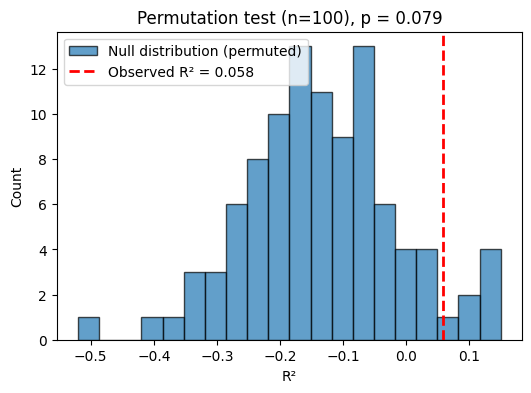

In [44]:
observed_r2 = result_combined["R2"]  
p_value = ((null_r2s >= observed_r2).sum() + 1) / (len(null_r2s) + 1)

print(f"Observed R²s:  {observed_r2:.3f}")
print(f"Mean null R²s: {null_r2s.mean():.3f}")
print(f"percentile: {np.percentile(null_r2s, 95):.3f}")
print(f"p-value: {p_value:.3f}")

plt.figure(figsize=(6, 4))
plt.hist(null_r2s, bins=20, edgecolor='black', alpha=0.7, label='Null distribution (permuted)')
plt.axvline(observed_r2, color='red', linestyle='--', linewidth=2, label=f'Observed R² = {observed_r2:.3f}')
plt.xlabel("R²")
plt.ylabel("Count")
plt.title(f"Permutation test (n={100}), p = {p_value:.3f}")
plt.legend()
plt.savefig("permutation_test.png", dpi=300, bbox_inches='tight')
plt.show()

In [21]:

def bootstrap_from_saved_predictions(pred_files, n_boot=10000, seed=42):
    dfs = {name: pd.read_csv(path) for name, path in pred_files.items()}
    rng = np.random.RandomState(seed)
    n = len(next(iter(dfs.values())))
    idx_matrix = rng.randint(0, n, size=(n_boot, n))

    results = {}
    for name, df in dfs.items():
        y, p = df["actual_temp"].values, df["predicted_temp"].values
        baseline = np.array([(y.sum() - y[i]) / (n - 1) for i in range(n)])
        d2_vs_baseline = (y - p) ** 2 - (y - baseline) ** 2

        r2s, rmses, sps, diffs_baseline = [], [], [], []
        for idx in idx_matrix:
            yi, pi = y[idx], p[idx]
            r2s.append(r2_score(yi, pi))
            rmses.append(np.sqrt(mean_squared_error(yi, pi)))
            sp = spearmanr(yi, pi).correlation
            sps.append(sp if not np.isnan(sp) else 0.0)
            diffs_baseline.append(d2_vs_baseline[idx].mean())
        results[name] = {
            "R2_CI": tuple(np.percentile(r2s, [2.5, 97.5])),
            "RMSE_CI": tuple(np.percentile(rmses, [2.5, 97.5])),
            "Spearman_CI": tuple(np.percentile(sps, [2.5, 97.5])),
            "MSE_diff_vs_baseline_CI": tuple(np.percentile(diffs_baseline, [2.5, 97.5])),
        }

   
    names = list(dfs.keys())
    for i in range(len(names)):
        for j in range(i + 1, len(names)):
            a, b = names[i], names[j]
            diffs = []
            for idx in idx_matrix:
                mse_a = mean_squared_error(dfs[a]["actual_temp"].values[idx], dfs[a]["predicted_temp"].values[idx])
                mse_b = mean_squared_error(dfs[b]["actual_temp"].values[idx], dfs[b]["predicted_temp"].values[idx])
                diffs.append(mse_a - mse_b)
            results[f"{a}_vs_{b}_MSE_diff_CI"] = tuple(np.percentile(diffs, [2.5, 97.5]))

    return results



pred_files = {
    "AAC": "gox_samples_predictions_aac.csv",
    "ESM2": "gox_samples_predictions_esm.csv",
    "Combined": "gox_samples_predictions_combined.csv",
}

ci_results = bootstrap_from_saved_predictions(pred_files)


In [22]:
ci_results

{'AAC': {'R2_CI': (-0.5549184363765908, 0.20201622829138674),
  'RMSE_CI': (11.44669825742325, 16.15325136267518),
  'Spearman_CI': (-0.13032630228846204, 0.5009490042920131),
  'MSE_diff_vs_baseline_CI': (-57.7559823838293, 66.15668579190994)},
 'ESM2': {'R2_CI': (-0.19220503355980303, 0.12655797642248262),
  'RMSE_CI': (10.958662501887282, 15.378757295106556),
  'Spearman_CI': (-0.09026034557355708, 0.46987179684913993),
  'MSE_diff_vs_baseline_CI': (-37.350228408712596, 12.536862531280736)},
 'Combined': {'R2_CI': (-0.18596115987639927, 0.18641829204112093),
  'RMSE_CI': (10.967317724638939, 14.87044086304379),
  'Spearman_CI': (-0.01156216859913443, 0.5606771137425349),
  'MSE_diff_vs_baseline_CI': (-51.17407875411145, 12.82481970874961)},
 'AAC_vs_ESM2_MSE_diff_CI': (-28.85349766835545, 66.19611208118106),
 'AAC_vs_Combined_MSE_diff_CI': (-36.07532144513886, 84.59831913089684),
 'ESM2_vs_Combined_MSE_diff_CI': (-24.811839025226433, 38.61067308072494)}

In [40]:
results_summary ={
    'baseline_mean': {'method': 'Mean predictor (LOOCV)', 'RMSE': baseline_rmse_loo, 'R2':None, 'Spearman': None},
    'aac_esm2_combined': {'method': 'AAC+ESM2, PCA+LightGBM, Optuna', **result_combined},
    'aac_only': {'method': 'AAC only, LightGBM, Optuna', **result_aac},
    'esm2_only': {'method': 'ESM2 only, PCA+LightGBM, Optuna', **result_esm},
    'combined_no_general_filter': {'method': 'AAC+ESM2, PCA+LightGBM, Optuna', **summarize_predictions(preds_combined_nofilter)},
    'aac_no_general_filter': {'method': 'AAC only, LightGBM, Optuna', **summarize_predictions(preds_aac_nofilter)},
    'esm2_no_general_filter': {'method': 'ESM2 only, PCA+LightGBM, Optuna', **summarize_predictions(preds_esm_nofilter)}
}

with open('gox_results_summary.json', 'w') as f:
    json.dump(results_summary, f, indent=2, ensure_ascii=False)

results_df = pd.DataFrame(results_summary).T
results_df.to_csv('gox_final_results_table.csv')
print(results_df)

                                                     method       RMSE  \
baseline_mean                        Mean predictor (LOOCV)  13.641142   
aac_esm2_combined            AAC+ESM2, PCA+LightGBM, Optuna  12.948439   
aac_only                         AAC only, LightGBM, Optuna  13.743661   
esm2_only                   ESM2 only, PCA+LightGBM, Optuna  13.175364   
combined_no_general_filter   AAC+ESM2, PCA+LightGBM, Optuna  13.156661   
aac_no_general_filter            AAC only, LightGBM, Optuna  13.601551   
esm2_no_general_filter      ESM2 only, PCA+LightGBM, Optuna   13.15974   

                                  R2  Spearman  
baseline_mean                   None      None  
aac_esm2_combined           0.058492  0.300029  
aac_only                   -0.060704  0.203916  
esm2_only                   0.025203  0.201689  
combined_no_general_filter  0.027968   0.22043  
aac_no_general_filter      -0.038882  0.199747  
esm2_no_general_filter      0.027513  0.209792  


In [41]:
gox = pd.read_csv('gox_final_results_table.csv')
gox.head()

,Unnamed: 0,method,RMSE,R2,Spearman
0,baseline_mean,Mean predictor (LOOCV),13.641142,NaN,NaN
1,aac_esm2_combined,"AAC+ESM2, PCA+LightGBM, Optuna",12.948439,0.058492,0.300029
2,aac_only,"AAC only, LightGBM, Optuna",13.743661,-0.060704,0.203916
3,esm2_only,"ESM2 only, PCA+LightGBM, Optuna",13.175364,0.025203,0.201689
4,combined_no_general_filter,"AAC+ESM2, PCA+LightGBM, Optuna",13.156661,0.027968,0.220430


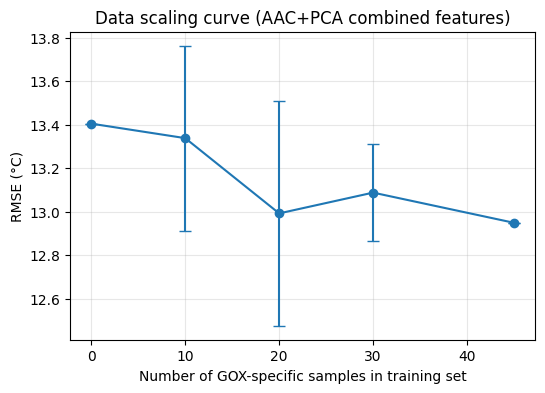

In [42]:
plt.figure(figsize=(6, 4))
plt.errorbar(scaling_df['k_gox_samples'], scaling_df['rmse_mean'], yerr=scaling_df['rmse_std'], marker='o', capsize=4)
plt.xlabel("Number of GOX-specific samples in training set")
plt.ylabel("RMSE (°C)")
plt.title('Data scaling curve (AAC+PCA combined features)')
plt.grid(alpha=0.3)
plt.savefig('scaling_curve.png', dpi=300, bbox_inches='tight')
plt.show()

In [34]:
import lightgbm, sklearn, torch, esm, optuna, pandas, scipy, numpy
for m in [lightgbm, sklearn, torch, esm, optuna, pandas, scipy, numpy]:
    print(m.__name__, m.__version__)

lightgbm 4.6.0
sklearn 1.3.2
torch 2.4.1+cpu
esm 2.0.0
optuna 4.5.0
pandas 2.0.3
scipy 1.10.1
numpy 1.24.4


In [43]:
import sys
print(sys.version)

3.8.8 (tags/v3.8.8:024d805, Feb 19 2021, 13:18:16) [MSC v.1928 64 bit (AMD64)]
